In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
tickers = ["CW8.PA", "IUSQ.DE", "PSP5.PA", "PUST.PA", "ETZ.PA",
           "AI.PA", "TTE.PA", "SAN.PA", "BN.PA", "ORA.PA", "ENGI.PA"]

prix = yf.download(tickers, start="2021-01-01", end="2026-10-28")["Close"]
prix.head()

[*********************100%***********************]  11 of 11 completed


Ticker,AI.PA,BN.PA,CW8.PA,ENGI.PA,ETZ.PA,IUSQ.DE,ORA.PA,PSP5.PA,PUST.PA,SAN.PA,TTE.PA
Date,,,,,,,,,,,
2021-01-04,91.637169,44.499306,327.290100,8.304383,11.346,51.560001,6.915305,24.906000,41.040001,61.398094,24.755535
2021-01-05,90.663383,44.662910,327.683990,8.181163,11.330,51.860001,6.894455,24.945999,41.084999,61.390312,25.406900
2021-01-06,90.864853,45.055550,332.530396,8.511912,11.510,52.410000,7.012607,25.350000,41.195000,61.017262,26.523531
2021-01-07,91.570015,44.352070,334.638489,8.476242,11.532,52.810001,7.165509,25.577999,41.630001,60.403282,26.813429
2021-01-08,92.107277,43.370468,337.027313,8.628646,11.614,53.299999,7.064732,25.684999,42.099998,61.234879,26.831320


In [15]:
print(prix.shape)
print(prix.isna().sum())
print(prix.notna().idxmax())

(1491, 11)
Ticker
AI.PA       0
BN.PA       0
CW8.PA      1
ENGI.PA     0
ETZ.PA      1
IUSQ.DE    10
ORA.PA      0
PSP5.PA     1
PUST.PA     1
SAN.PA      0
TTE.PA      0
dtype: int64
Ticker
AI.PA     2021-01-04
BN.PA     2021-01-04
CW8.PA    2021-01-04
ENGI.PA   2021-01-04
ETZ.PA    2021-01-04
IUSQ.DE   2021-01-04
ORA.PA    2021-01-04
PSP5.PA   2021-01-04
PUST.PA   2021-01-04
SAN.PA    2021-01-04
TTE.PA    2021-01-04
dtype: datetime64[s]


In [16]:
prix = prix.ffill()
rendements = prix.pct_change().dropna()
print(rendements.isna().sum())

Ticker
AI.PA      0
BN.PA      0
CW8.PA     0
ENGI.PA    0
ETZ.PA     0
IUSQ.DE    0
ORA.PA     0
PSP5.PA    0
PUST.PA    0
SAN.PA     0
TTE.PA     0
dtype: int64


In [17]:
vol = rendements.std() * (252 ** 0.5)
print(vol.sort_values(ascending=False))

Ticker
TTE.PA     0.241972
SAN.PA     0.225176
ENGI.PA    0.212510
PUST.PA    0.196503
BN.PA      0.188884
AI.PA      0.184819
ORA.PA     0.170219
PSP5.PA    0.147303
ETZ.PA     0.140912
CW8.PA     0.137542
IUSQ.DE    0.135899
dtype: float64


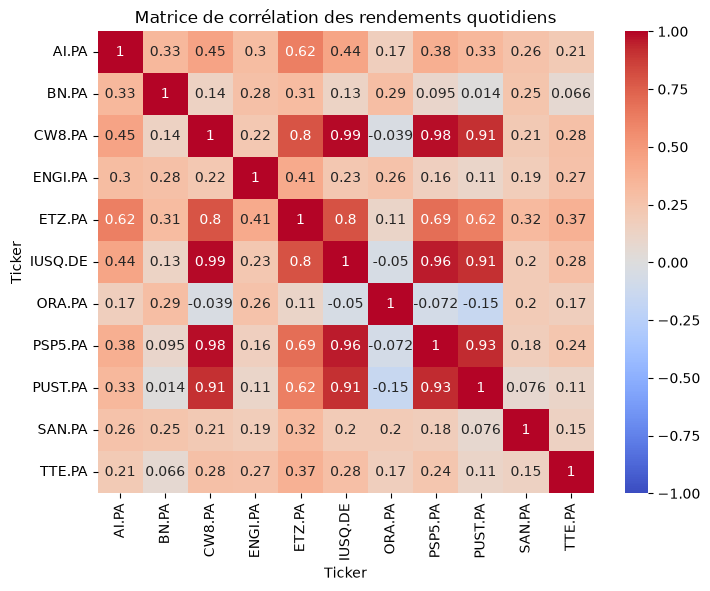

In [18]:
correlations = rendements.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation des rendements quotidiens")
plt.show()

In [21]:
poids = 0.0909
rendement_ptf = (rendements[["CW8.PA", "IUSQ.DE", "PSP5.PA", "PUST.PA", "ETZ.PA",
           "AI.PA", "TTE.PA", "SAN.PA", "BN.PA", "ORA.PA", "ENGI.PA"]] * poids).sum(axis=1)

vol_ptf = rendement_ptf.std() * (252 ** 0.5)
moyenne_vols = vol[["CW8.PA", "IUSQ.DE", "PSP5.PA", "PUST.PA", "ETZ.PA",
           "AI.PA", "TTE.PA", "SAN.PA", "BN.PA", "ORA.PA", "ENGI.PA"]].mean()

print("Volatilité du portefeuille :", vol_ptf)
print("Moyenne des volatilités   :", moyenne_vols)

Volatilité du portefeuille : 0.10779810972310493
Moyenne des volatilités   : 0.18015808014217452
